# 03 · Modelado: baselines y CNNs preentrenadas

**Fase CRISP-DM:** 4 – Modelado

Los entrenamientos son largos, por lo que se ejecutan como scripts (`run_experiments.sh`, que llama a
`src/baselines.py` y `src/train.py`) y este notebook carga y analiza sus resultados
(`results/metrics.csv`, `results/history/*.csv`, `results/oof/*.csv`).

**Protocolo experimental**
- Validación: 5 folds agrupados por paciente (sin fuga). Fase de *screening* en el fold 0 (~3 400
  EEG de validación) para comparar arquitecturas y ablaciones; las mejores se entrenan en los 5 folds.
- Pérdida: divergencia KL entre la distribución de votos y la salida softmax.
- Optimización: AdamW (wd 1e-2), OneCycle con calentamiento coseno, bf16, batch 32, recorte de gradiente.
- **Etapa 1**: 12 épocas con todas las muestras. **Etapa 2**: 4 épocas con lr/10 solo en muestras
  con ≥10 votos (más confiables, según el EDA).
- Métricas: **KL** (oficial, menor es mejor) sobre todas las muestras y sobre las de alta calidad
  (`kl_hq`), accuracy y F1-macro de la clase mayoritaria y AUC macro uno-contra-resto.

Referencia: en la competencia el primer lugar obtuvo ≈0.27 de KL en el leaderboard privado, con
grandes ensambles. Ese test oculto estaba compuesto por muestras de alto acuerdo, por lo que la
comparación más cercana es nuestra `kl_hq` en validación cruzada — aunque no es directamente
equivalente (otro conjunto de pacientes y otra forma de consolidar las sub-ventanas).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../.."))  # raíz del repo (notebooks/iteracion_2/ -> ../..)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import RESULTS_DIR, FIGURES_DIR, OOF_DIR, TARGETS, CLASSES
from src.evaluate import all_metrics
from src.viz import set_style, PALETTE
set_style()
FIG = FIGURES_DIR / "modelado"; FIG.mkdir(exist_ok=True, parents=True)
metrics = pd.read_csv(RESULTS_DIR / "metrics.csv")
cols = ["experiment", "model", "pretrained", "input", "folds", "stage", "epochs", "n_valid", "train_min",
        "kl", "kl_hq", "accuracy", "accuracy_hq", "macro_f1", "macro_auc"]
metrics[cols].sort_values("kl").round(4)

,experiment,model,pretrained,input,folds,stage,epochs,n_valid,train_min,kl,kl_hq,accuracy,accuracy_hq,macro_f1,macro_auc
21,cv_effb0,efficientnet_b0.ra_in1k,True,both,all,2,16,17089,88.3,0.6230,0.3846,0.7057,0.7259,0.6235,0.9154
23,cv_convnext_t,convnext_tiny.fb_in22k_ft_in1k,True,both,all,2,16,17089,222.9,0.6292,0.3987,0.7092,0.7224,0.6242,0.9135
9,f0_effb2,efficientnet_b2.ra_in1k,True,both,0,2,16,3418,19.4,0.6457,0.3489,0.7089,0.7576,0.6224,0.9071
5,f0_effb0,efficientnet_b0.ra_in1k,True,both,0,2,16,3418,13.4,0.6478,0.3515,0.7074,0.7567,0.6207,0.9094
13,f0_regnety016,regnety_016.tv2_in1k,True,both,0,2,16,3418,19.8,0.6550,0.3513,0.6989,0.7548,0.6058,0.9068
11,f0_convnext_t,convnext_tiny.fb_in22k_ft_in1k,True,both,0,2,16,3418,22.4,0.6551,0.3683,0.7145,0.7539,0.6245,0.9081
20,cv_effb0_s1,efficientnet_b0.ra_in1k,True,both,all,1,12,17089,88.3,0.6828,0.5113,0.7089,0.6985,0.6341,0.9116
12,f0_regnety016_s1,regnety_016.tv2_in1k,True,both,0,1,12,3418,19.8,0.6862,0.4530,0.7156,0.7373,0.6278,0.9063
19,f0_effb0_eeg,efficientnet_b0.ra_in1k,True,eeg,0,2,16,3418,7.5,0.6886,0.3648,0.6957,0.7493,0.5920,0.8950
8,f0_effb2_s1,efficientnet_b2.ra_in1k,True,both,0,1,12,3418,19.4,0.6898,0.4453,0.7077,0.7309,0.6312,0.9051


## 1. Baselines (5 folds)
- **prior_uniforme**: predice 1/6 para cada clase.
- **prior_clases**: predice la distribución media de votos del entrenamiento.
- **logreg_bandas / hgb_bandas**: regresión logística y *gradient boosting* sobre ~60 features clásicas
  (potencia relativa por banda y región, line-length, asimetría), entrenados con etiquetas suaves
  (cada muestra replicada por clase con peso = fracción de votos).

Para comparar con las CNNs del screening se recalculan también sobre el fold 0.

In [2]:
def oof_metrics(name, fold=None):
    df = pd.read_csv(OOF_DIR / f"{name}.csv")
    if fold is not None:
        df = df[df.fold == fold]
    return all_metrics(df[TARGETS].to_numpy(), df[[f"pred_{t}" for t in TARGETS]].to_numpy(), df.total_votes)

base = ["prior_uniforme", "prior_clases", "logreg_bandas", "hgb_bandas"]
pd.DataFrame({n: {**{f"{k}_5f": v for k, v in oof_metrics(n).items() if k in ("kl", "kl_hq", "accuracy")},
                  **{f"{k}_f0": v for k, v in oof_metrics(n, 0).items() if k in ("kl", "kl_hq", "accuracy")}}
              for n in base}).T.round(4)

,kl_5f,accuracy_5f,kl_hq_5f,kl_f0,accuracy_f0,kl_hq_f0
prior_uniforme,1.4620,0.1638,1.1690,1.4687,0.1638,1.2008
prior_clases,1.2632,0.4187,0.9086,1.2606,0.4187,0.9260
logreg_bandas,1.0611,0.4994,0.8141,1.0706,0.5211,0.8255
hgb_bandas,0.8821,0.5688,0.6558,0.9618,0.5389,0.6661


## 2. Screening de CNNs preentrenadas (fold 0)

In [3]:
scr = metrics[metrics.folds.astype(str) == "0"].copy()
for n in base:
    m = oof_metrics(n, 0)
    scr = pd.concat([scr, pd.DataFrame([{"experiment": n, "stage": 0, **m}])])
scr["grupo"] = np.select(
    [scr.experiment.isin(base), scr.experiment.str.contains("scratch|kaggle|eeg")],
    ["baseline", "ablación"], "arquitectura")
final = scr[(scr.stage != 1)].sort_values("kl")
final[["experiment", "grupo", "kl", "kl_hq", "accuracy", "macro_f1", "macro_auc", "train_min"]].round(4)

,experiment,grupo,kl,kl_hq,accuracy,macro_f1,macro_auc,train_min
9,f0_effb2,arquitectura,0.6457,0.3489,0.7089,0.6224,0.9071,19.4
5,f0_effb0,arquitectura,0.6478,0.3515,0.7074,0.6207,0.9094,13.4
13,f0_regnety016,arquitectura,0.6550,0.3513,0.6989,0.6058,0.9068,19.8
11,f0_convnext_t,arquitectura,0.6551,0.3683,0.7145,0.6245,0.9081,22.4
19,f0_effb0_eeg,ablación,0.6886,0.3648,0.6957,0.5920,0.8950,7.5
7,f0_resnet34,arquitectura,0.7172,0.4384,0.6764,0.5720,0.8881,10.3
15,f0_effb0_scratch,ablación,0.7427,0.3941,0.6682,0.5778,0.8856,14.1
17,f0_effb0_kaggle,ablación,0.7510,0.4295,0.6706,0.5761,0.8819,7.6
0,hgb_bandas,baseline,0.9618,0.6661,0.5389,0.4174,0.8053,NaN
0,logreg_bandas,baseline,1.0706,0.8255,0.5211,0.3861,0.7447,NaN


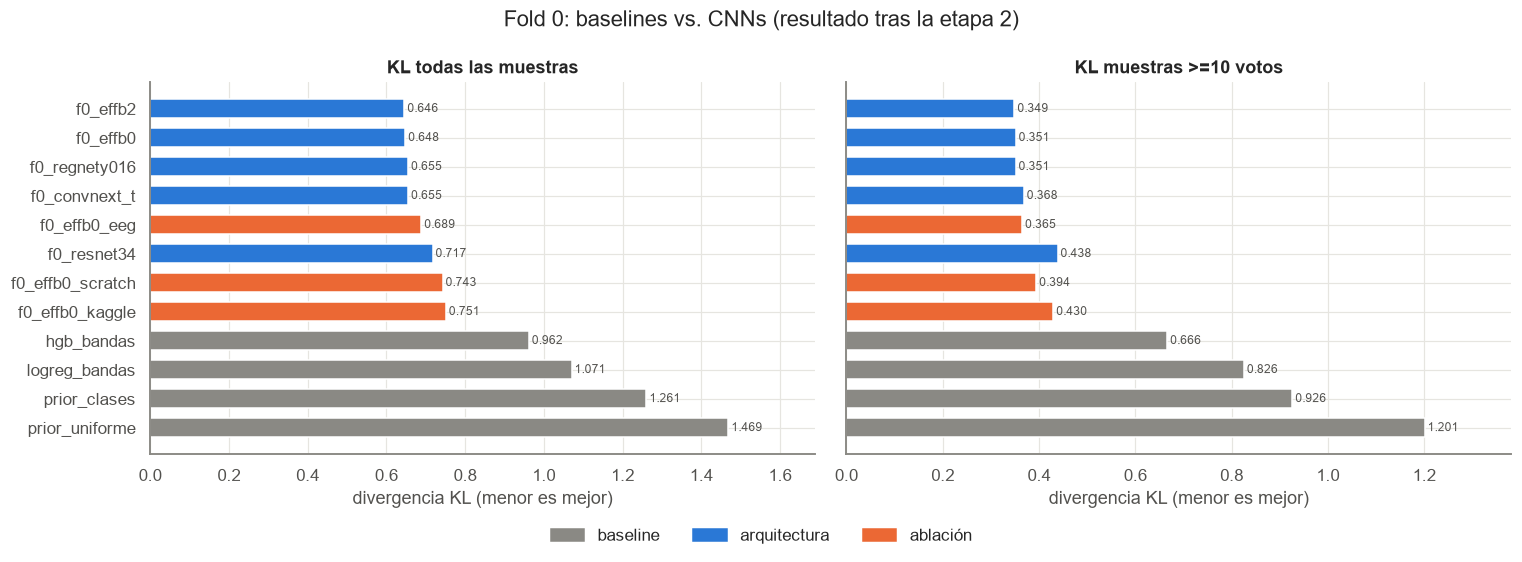

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
order = final.sort_values("kl", ascending=False)
colors = {"baseline": "#8a8984", "arquitectura": PALETTE[0], "ablación": PALETTE[1]}
for ax, col, title in [(axes[0], "kl", "KL todas las muestras"), (axes[1], "kl_hq", "KL muestras >=10 votos")]:
    ax.barh(order.experiment, order[col], color=[colors[g] for g in order.grupo], height=0.65)
    for y, v in enumerate(order[col]):
        ax.text(v, y, f" {v:.3f}", va="center", fontsize=8, color="#52514e")
    ax.set_title(title); ax.set_xlabel("divergencia KL (menor es mejor)"); ax.margins(x=0.15)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
fig.legend(handles, colors.keys(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Fold 0: baselines vs. CNNs (resultado tras la etapa 2)")
fig.tight_layout(); fig.savefig(FIG / "screening_fold0.png"); plt.show()

**Lectura del screening (fold 0, KL todas / KL ≥10 votos):**
- Todas las CNNs preentrenadas superan con amplitud al mejor baseline clásico
  (HGB 0.962 / 0.666 en este fold): **EfficientNet-B2 0.646 / 0.349, EfficientNet-B0 0.648 / 0.351,
  RegNetY-016 0.655 / 0.351, ConvNeXt-T 0.655 / 0.368**; ResNet34 queda atrás (0.717 / 0.438).
  Entre las cuatro mejores las diferencias (~0.01) están dentro del ruido de un solo fold.
- **Transfer learning:** la misma EfficientNet-B0 sin pesos de ImageNet empeora a 0.743 / 0.394
  (+0.095 KL). Aunque los espectrogramas no son fotos, los filtros preentrenados de bordes y texturas
  sí se transfieren y aceleran la convergencia.
- **Fuentes de entrada:** solo espectrogramas de Kaggle 0.751 / 0.430; solo espectrogramas del EEG
  0.689 / 0.365; ambos 0.648 / 0.351. El EEG crudo (50 s, mayor resolución temporal) aporta más que
  el espectrograma de 10 min, y combinarlos es mejor que cualquiera por separado.
- EfficientNet-B0 ofrece el mejor balance costo/desempeño (~53 s por época vs. ~78 s B2 y ~95 s ConvNeXt-T).

**Selección para validación cruzada completa:** se evaluaron ensambles 50/50 de pares en el fold 0.
El mejor par fue **EfficientNet-B0 + ConvNeXt-T (0.602 / 0.321)**, mejor que B0 + B2 (0.611 / 0.321)
pese a que ConvNeXt-T es individualmente algo peor: al ser una familia de arquitectura distinta sus
errores son menos correlacionados. Estos dos modelos se entrenan en los 5 folds.

## 3. Curvas de entrenamiento

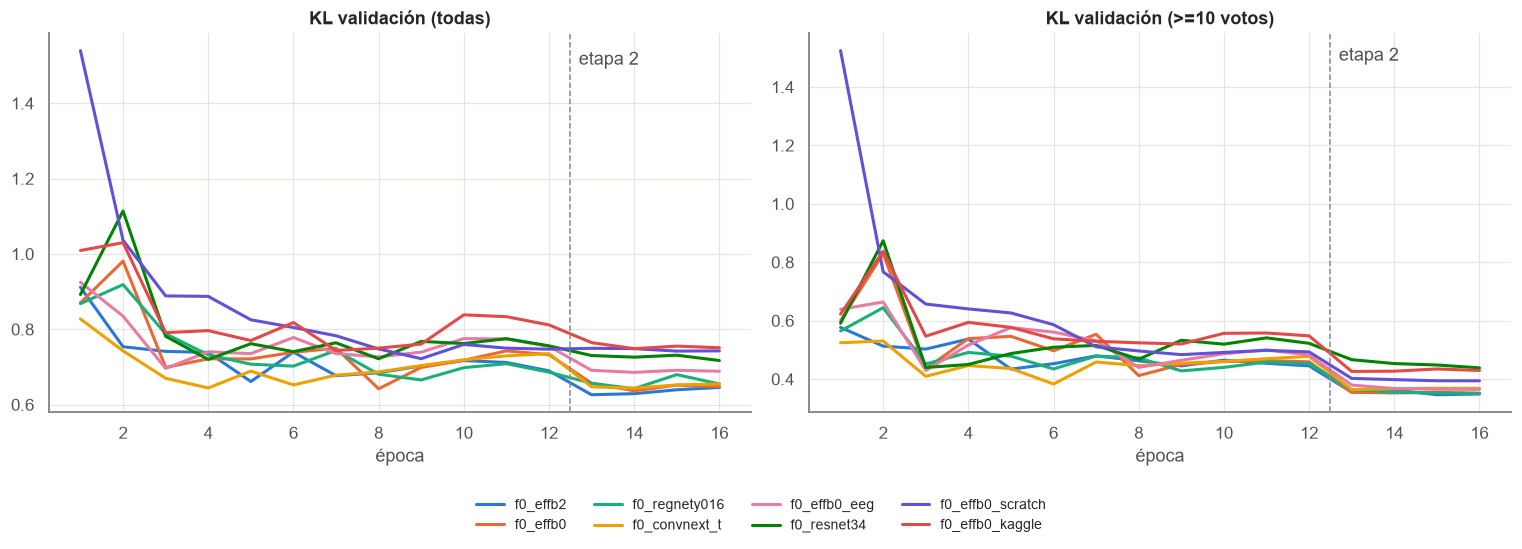

In [5]:
hist_dir = RESULTS_DIR / "history"
names = [n for n in final.experiment if (hist_dir / f"{n}.csv").exists()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for i, n in enumerate(names[:8]):
    h = pd.read_csv(hist_dir / f"{n}.csv")
    h = h[h.fold == h.fold.min()].reset_index(drop=True)
    x = np.arange(1, len(h) + 1)
    axes[0].plot(x, h.valid_kl, lw=2, color=PALETTE[i % 8], label=n)
    axes[1].plot(x, h.valid_kl_hq, lw=2, color=PALETTE[i % 8], label=n)
s1 = int((h.stage == 1).sum())
for ax, t in zip(axes, ["KL validación (todas)", "KL validación (>=10 votos)"]):
    ax.axvline(s1 + 0.5, color="#8a8984", ls="--", lw=1); ax.text(s1 + 0.7, ax.get_ylim()[1] * 0.97, "etapa 2", color="#52514e", va="top", ha="left")
    ax.set_title(t); ax.set_xlabel("época")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.12)); fig.savefig(FIG / "curvas_validacion.png"); plt.show()

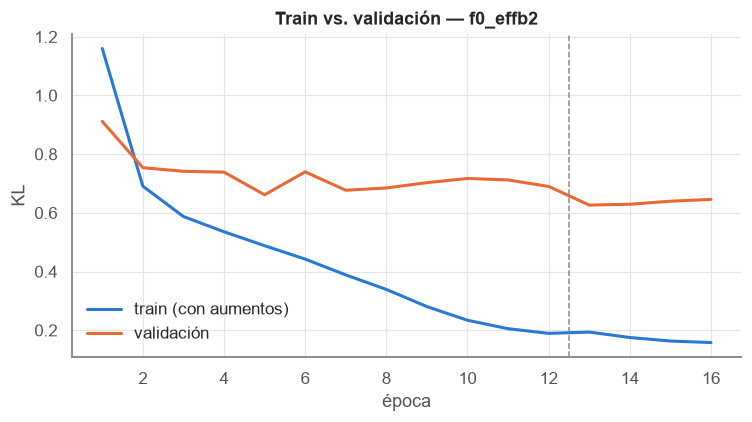

In [6]:
h = pd.read_csv(hist_dir / f"{names[0]}.csv"); h = h[h.fold == h.fold.min()]
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(1, len(h) + 1)
ax.plot(x, h.train_kl, lw=2, color=PALETTE[0], label="train (con aumentos)")
ax.plot(x, h.valid_kl, lw=2, color=PALETTE[1], label="validación")
ax.axvline(s1 + 0.5, color="#8a8984", ls="--", lw=1)
ax.set_title(f"Train vs. validación — {names[0]}"); ax.set_xlabel("época"); ax.set_ylabel("KL"); ax.legend()
fig.tight_layout(); plt.show()

- En la etapa 1 la KL de validación se estanca hacia las épocas 3–8 mientras la de entrenamiento sigue
  bajando (≈0.19 al final): hay **sobreajuste** y la validación oscila bastante entre épocas por el ruido
  de las etiquetas con pocos votos.
- La **etapa 2** produce el salto más grande, sobre todo en el subconjunto de alta calidad.
- Nota: en la etapa 2 el train KL sube porque se entrena solo con muestras de alto acuerdo, cuyas
  distribuciones son más difíciles (más repartidas entre clases vecinas), no por sobreajuste.

## 4. Efecto del entrenamiento en dos etapas

In [7]:
two = metrics[metrics.stage.isin([1, 2])].copy()
two["base"] = two.experiment.str.replace("_s1$", "", regex=True)
pv = two.pivot_table(index="base", columns="stage", values=["kl", "kl_hq"])
pv.columns = [f"{a}_etapa{b}" for a, b in pv.columns]
pv["Δkl"] = pv.kl_etapa2 - pv.kl_etapa1
pv["Δkl_hq"] = pv.kl_hq_etapa2 - pv.kl_hq_etapa1
pv.round(4)

,kl_etapa1,kl_etapa2,kl_hq_etapa1,kl_hq_etapa2,Δkl,Δkl_hq
base,,,,,,
cv_convnext_t,0.6939,0.6292,0.5084,0.3987,-0.0647,-0.1097
cv_effb0,0.6828,0.6230,0.5113,0.3846,-0.0597,-0.1267
f0_convnext_t,0.7353,0.6551,0.4779,0.3683,-0.0802,-0.1096
f0_effb0,0.7327,0.6478,0.4591,0.3515,-0.0849,-0.1076
f0_effb0_eeg,0.7549,0.6886,0.4822,0.3648,-0.0663,-0.1174
f0_effb0_kaggle,0.8116,0.7510,0.5479,0.4295,-0.0605,-0.1184
f0_effb0_scratch,0.7472,0.7427,0.4931,0.3941,-0.0045,-0.0990
f0_effb2,0.6898,0.6457,0.4453,0.3489,-0.0441,-0.0964
f0_regnety016,0.6862,0.6550,0.4530,0.3513,-0.0312,-0.1018


## 5. Validación cruzada completa (5 folds) y ensamble

In [8]:
cv = metrics[metrics.folds.astype(str) == "all"].sort_values("kl")
cv[cols].round(4)

,experiment,model,pretrained,input,folds,stage,epochs,n_valid,train_min,kl,kl_hq,accuracy,accuracy_hq,macro_f1,macro_auc
21,cv_effb0,efficientnet_b0.ra_in1k,True,both,all,2,16,17089,88.3,0.6230,0.3846,0.7057,0.7259,0.6235,0.9154
23,cv_convnext_t,convnext_tiny.fb_in22k_ft_in1k,True,both,all,2,16,17089,222.9,0.6292,0.3987,0.7092,0.7224,0.6242,0.9135
20,cv_effb0_s1,efficientnet_b0.ra_in1k,True,both,all,1,12,17089,88.3,0.6828,0.5113,0.7089,0.6985,0.6341,0.9116
22,cv_convnext_t_s1,convnext_tiny.fb_in22k_ft_in1k,True,both,all,1,12,17089,222.9,0.6939,0.5084,0.7093,0.6985,0.6339,0.9107
3,hgb_bandas,hgb_bandas,False,features,all,0,0,17089,0.0,0.8821,0.6558,0.5688,0.5771,0.4673,0.8346
2,logreg_bandas,logreg_bandas,False,features,all,0,0,17089,0.0,1.0611,0.8141,0.4994,0.5263,0.3544,0.7556
1,prior_clases,prior_clases,False,features,all,0,0,17089,0.0,1.2632,0.9086,0.4187,0.5291,0.0984,0.4998
0,prior_uniforme,prior_uniforme,False,features,all,0,0,17089,0.0,1.4620,1.1690,0.1638,0.0337,0.0469,0.5000


In [9]:
cv_models = [e for e in cv.experiment if e.startswith("cv_") and not e.endswith("_s1")]
if len(cv_models) >= 2:
    dfs = [pd.read_csv(OOF_DIR / f"{n}.csv").sort_values("eeg_id").reset_index(drop=True) for n in cv_models]
    Y = dfs[0][TARGETS].to_numpy(); votes = dfs[0].total_votes
    preds = [d[[f"pred_{t}" for t in TARGETS]].to_numpy() for d in dfs]
    rows = {n: all_metrics(Y, p, votes) for n, p in zip(cv_models, preds)}
    best_w, best = None, 9
    for w in np.linspace(0, 1, 21):
        k = all_metrics(Y, w * preds[0] + (1 - w) * preds[1], votes)["kl"]
        if k < best: best, best_w = k, w
    ens = best_w * preds[0] + (1 - best_w) * preds[1]
    rows[f"ensamble ({best_w:.2f}·{cv_models[0]} + {1 - best_w:.2f}·{cv_models[1]})"] = all_metrics(Y, ens, votes)
    rows["ensamble 50/50"] = all_metrics(Y, (preds[0] + preds[1]) / 2, votes)
    out = dfs[0][["eeg_id", "patient_id", "fold", "total_votes"] + TARGETS].copy()
    out[[f"pred_{t}" for t in TARGETS]] = (preds[0] + preds[1]) / 2
    out.to_csv(OOF_DIR / "ensemble.csv", index=False)
    display(pd.DataFrame(rows).T.round(4))
    print("El peso óptimo se elige sobre los mismos OOF: el ensamble 50/50 es la estimación honesta.")

,kl,accuracy,macro_f1,macro_auc,kl_hq,accuracy_hq
cv_effb0,0.6230,0.7057,0.6235,0.9153,0.3846,0.7261
cv_convnext_t,0.6292,0.7093,0.6243,0.9135,0.3987,0.7226
ensamble (0.50·cv_effb0 + 0.50·cv_convnext_t),0.5757,0.7173,0.6331,0.9235,0.3474,0.7376
ensamble 50/50,0.5757,0.7173,0.6331,0.9235,0.3474,0.7376


El peso óptimo se elige sobre los mismos OOF: el ensamble 50/50 es la estimación honesta.


## 6. Conclusiones del modelado
Ver la sección de conclusiones en `04_evaluacion.ipynb` y `docs/informe_resultados.md`.